<a href="https://colab.research.google.com/github/andyotani/PCVK_Ganjil_26-27/blob/main/Jobsheet09/JS09_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum Morfologi

In [155]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [156]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

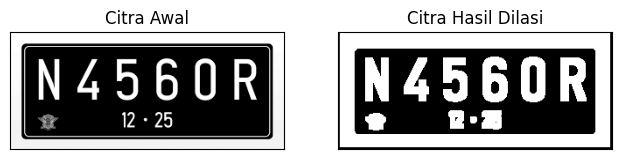

In [157]:
# fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari openCV
# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# Membaca citra
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

# Proses Dilasi dengan ukuran window (w) = 5
w = 5
imgD = dilasi_citra(thresh, w)

# Menampilkan Citra
plt.figure(figsize=(12, 4)) # Menambahkan figure size agar tampilan tidak terlalu kecil

plt.subplot(131)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi')
plt.xticks([])
plt.yticks([])

plt.show()

Kernel yang digunakan:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


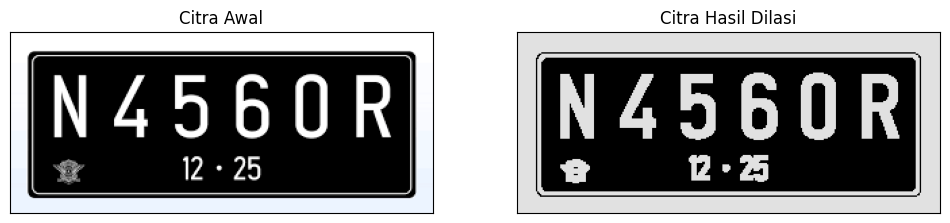

In [158]:
# Membuat program implementasi operasi dilasi Structuring Element Dilasi (SED) berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV
# Membaca citra
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png')
# img = cv2.imread('morp.jpg', 0) # Opsi alternatif jika ingin langsung grayscale

# Proses Thresholding (Binarisasi)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

# Membuat Structuring Element (Kernel) 3x3
kernel = np.ones((3, 3), np.uint8)
print("Kernel yang digunakan:\n", kernel)

# Proses Dilasi dengan library OpenCV
dilasi = cv2.dilate(thresh, kernel, iterations=1)

# Konversi BGR ke RGB agar warna gambar asli tampil benar di Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Menampilkan Citra
plt.figure(figsize=(12, 4)) # Mengatur ukuran tampilan gambar

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(dilasi, cmap='gray') # Menggunakan cmap='gray' karena citra hasil biner
plt.title('Citra Hasil Dilasi')
plt.xticks([])
plt.yticks([])

plt.show()

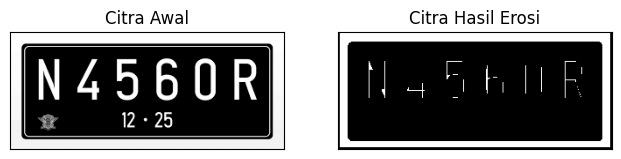

In [159]:
# fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV
# Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# Membaca citra
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

# Proses Erosi dengan ukuran window (k) = 5
k = 5
imgE = erosi_citra(thresh1, k)

# Menampilkan Citra
plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.show()

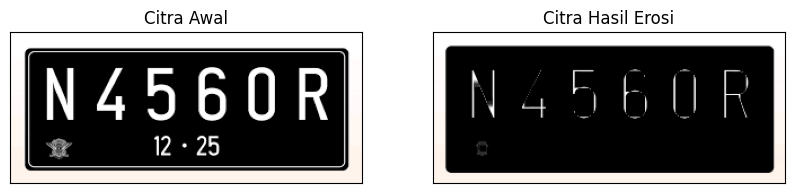

In [160]:
# EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png')
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img)
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(erosion)
plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

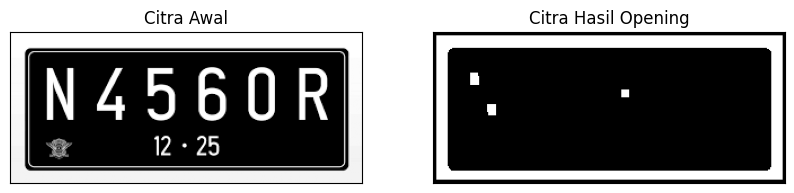

In [161]:
# --- Operasi Opening Tanpa Library ---
img_o = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret_o, thresh_o = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresh_o, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening')
plt.xticks([]), plt.yticks([])
plt.show()



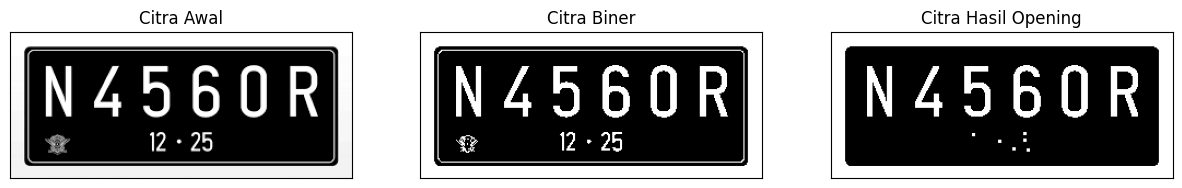

In [162]:
# --- Operasi Opening Dengan Library ---
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openm = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 4))
plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(openm, cmap='gray')
plt.title('Citra Hasil Opening')
plt.xticks([]), plt.yticks([])
plt.show()

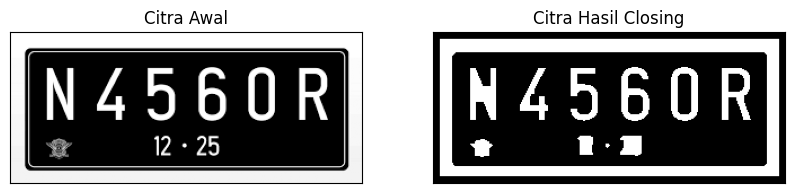

In [163]:
# --- Operasi Closing Tanpa Library ---
img_c = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret_c, thresh_c = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(thresh_c, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing')
plt.xticks([]), plt.yticks([])
plt.show()

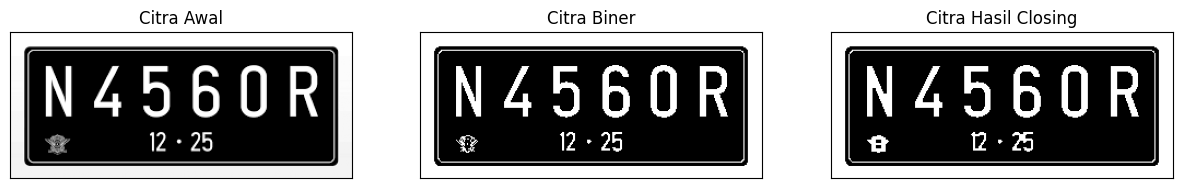

In [164]:
# --- Operasi Closing Dengan Library ---
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)

# Di modul tertulis "class = ..." (error karena class adalah keyword Python), diganti menjadi "closed"
closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 4))
plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(closed, cmap='gray')
plt.title('Citra Hasil Closing')
plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


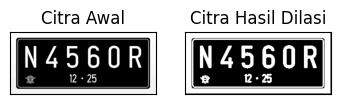

SED = Cross 5


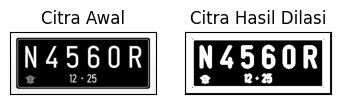

In [165]:

# Dilasi Cross SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w, w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w, w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


SED = Circle 3


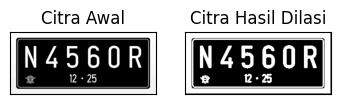

SED = Circle 5


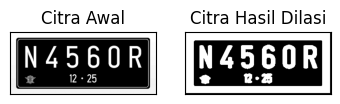

In [166]:
# Dilasi Circular SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


SE = Rectangle 3x5


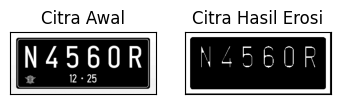

SE = Rectangle 5x7


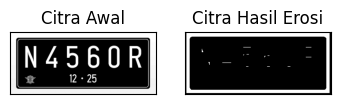

In [167]:
# Erosi Cross SE
def erosi_citra(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(
        cv2.MORPH_RECT, (p, l)
    )  # SE persegi panjang

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant2:j + constant2 + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)  #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


print('SE = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)  #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


SE = Line Vertikal 3


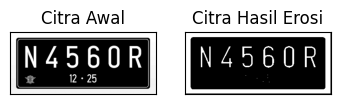

SE = Line Vertikal 5


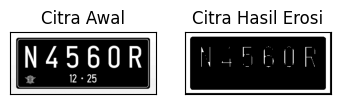

In [168]:

# Erosi Line Vertikal SE
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (1, k)
    )  # SE line vertikal

    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant:i + constant + 1,
                j - constant:j + constant + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)  #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


print('SE = Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.png', 0)  #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


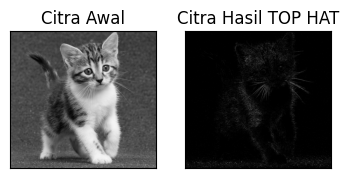

In [169]:
# TopHat
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, filterSize
)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

# cv2.imshow("original", input_image)
# cv2.imshow("tophat", tophat_img)
# cv2.waitKey(5000)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])

plt.show()


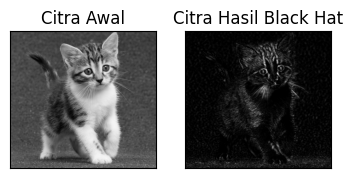

In [170]:
# BLACKHAT
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

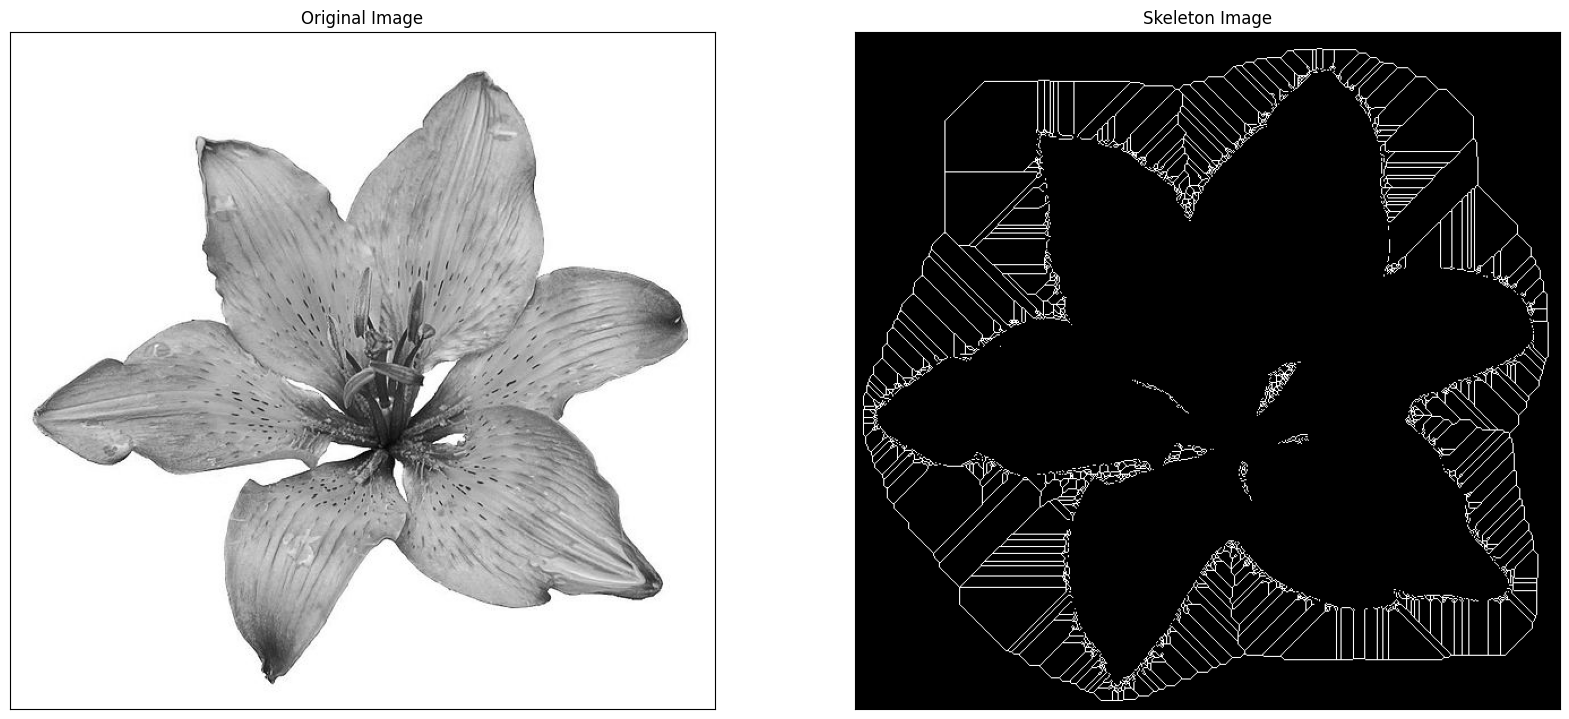

In [171]:
# Skeleton
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# True False to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# Skeletonize image
skeleton = skeletonize(binary_cp)

# Print images
plt.figure(figsize=(20, 20))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([])
plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()


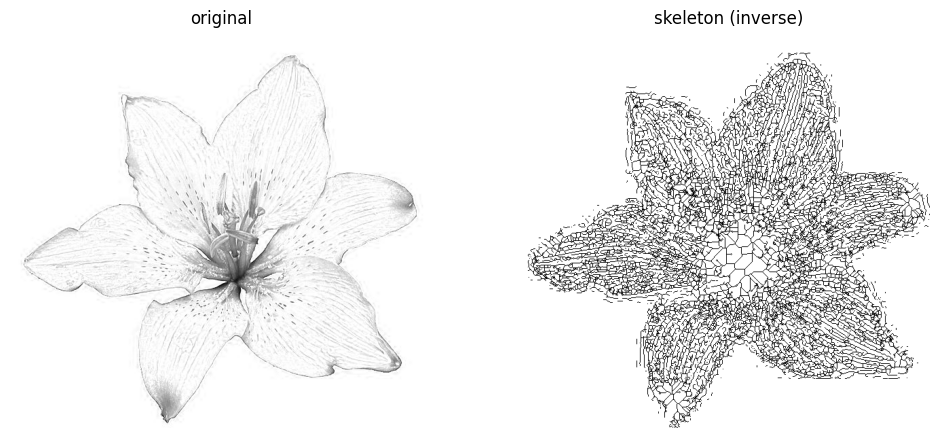

In [172]:
# Skeleton Inverse
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

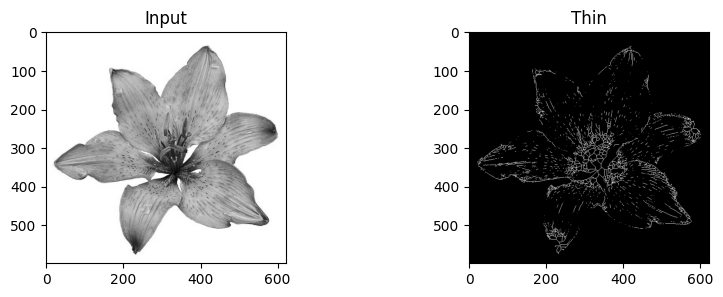

In [173]:
# Thickening
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

Tugas Praktikum

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


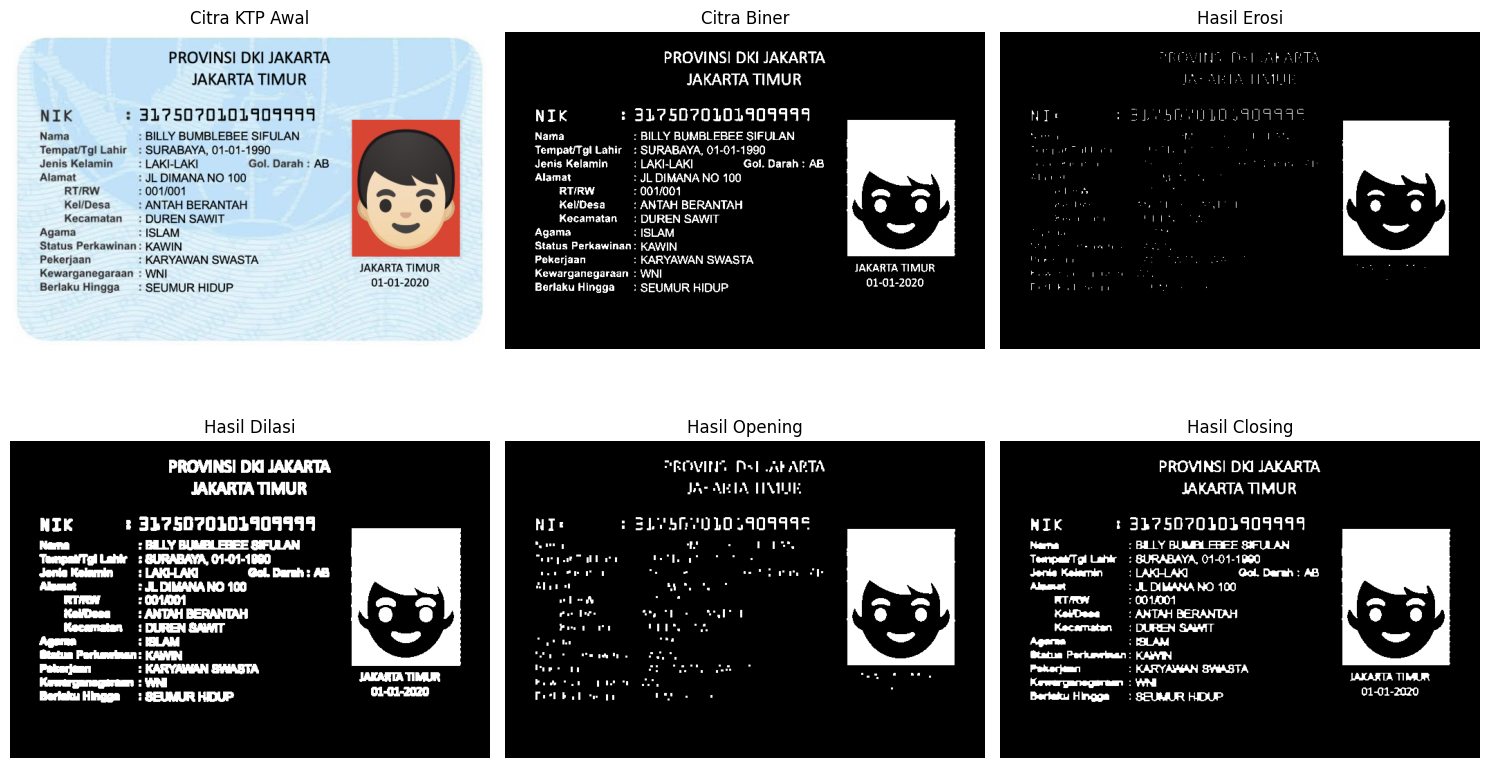

In [174]:
# Praktikum Morfologi pada Citra KTP

import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab import drive

# Menghubungkan Google Drive
drive.mount('/content/drive')

# Membaca citra KTP
# Sesuaikan lokasi file dengan dataset KTP Modul 7
path = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'
img = cv2.imread(path)

if img is None:
    raise FileNotFoundError(
        'Gambar KTP tidak ditemukan. Periksa kembali lokasi file.'
    )

# Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Mengubah citra grayscale menjadi citra biner
# Otsu digunakan untuk menentukan nilai threshold otomatis
_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Structuring Element berukuran 3 x 3
kernel = np.ones((3, 3), dtype=np.uint8)

# Operasi morfologi
erosi = cv2.erode(binary, kernel, iterations=1)
dilasi = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=1
)
closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel, iterations=1
)

# Menampilkan hasil pengolahan
plt.figure(figsize=(15, 9))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra KTP Awal')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(binary, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(erosi, cmap='gray')
plt.title('Hasil Erosi')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(dilasi, cmap='gray')
plt.title('Hasil Dilasi')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(opening, cmap='gray')
plt.title('Hasil Opening')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(closing, cmap='gray')
plt.title('Hasil Closing')
plt.axis('off')

plt.tight_layout()
plt.show()


## E. Tugas Praktikum Morfologi

### Tujuan Praktikum

Tugas praktikum ini bertujuan untuk menerapkan operasi morfologi pada citra KTP dari dataset Modul 7. Operasi ini digunakan untuk memperbaiki tampilan citra agar tulisan dan informasi pada KTP lebih jelas dan mudah dibaca. Mahasiswa juga dapat memahami pengaruh erosi, dilasi, opening, dan closing terhadap bentuk objek pada citra digital.

### Langkah-Langkah Praktikum

Citra KTP dibaca menggunakan library OpenCV pada Python, kemudian diubah menjadi grayscale dan citra biner untuk memisahkan tulisan dari latar belakang. Selanjutnya, operasi erosi, dilasi, opening, dan closing diterapkan menggunakan *structuring element* berukuran 3 × 3.

Hasil dari setiap operasi ditampilkan menggunakan Matplotlib, kemudian dibandingkan dengan citra awal untuk mengetahui perubahan yang terjadi dan menentukan operasi yang sesuai untuk membantu memperjelas tulisan pada KTP.

### Hasil dan Pembahasan

Operasi erosi berfungsi menipiskan objek, sedangkan dilasi digunakan untuk menebalkan objek dan membantu menyambungkan bagian tulisan yang terputus. Opening merupakan kombinasi erosi dan dilasi yang dapat mengurangi noise kecil, sementara closing merupakan kombinasi dilasi dan erosi yang membantu menutup celah kecil pada objek.

Pemilihan ukuran *structuring element* dan jumlah iterasi perlu diperhatikan karena dapat memengaruhi hasil pengolahan. Parameter yang sesuai dapat membantu menjaga bentuk tulisan agar tetap jelas dan mudah dibaca.

### Kesimpulan

Operasi morfologi memiliki fungsi yang berbeda dalam pengolahan citra digital. Erosi menipiskan objek, dilasi menebalkan objek, opening mengurangi noise kecil, dan closing menutup celah pada objek. Penerapan operasi tersebut pada citra KTP perlu disesuaikan dengan kondisi citra agar tulisan tetap utuh dan informasi di dalamnya dapat terbaca dengan baik.

link Github : http://github.com/andyotani/PCVK_Ganjil_26-27/blob/main/Jobsheet09/JS09_pcvk.ipynb